In [1]:
import pandas as pd
import numpy as np
import scipy
import sklearn
import shap
import lime
import streamlit

print("Environment verification successful!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)

Environment verification successful!
Pandas: 2.3.3
NumPy: 2.0.2
Scikit-learn: 1.6.1
SHAP: 0.49.1


In [2]:
from pathlib import Path

data_path = Path("../data/raw/Chronic_Kidney_Disease/Chronic_Kidney_Disease_full.arff")

print("Dataset exists:", data_path.exists())
print("Dataset path:", data_path)

Dataset exists: True
Dataset path: ../data/raw/Chronic_Kidney_Disease/Chronic_Kidney_Disease_full.arff


In [8]:
import re
import csv
import pandas as pd

# Read ARFF file
with open(data_path, "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

# -----------------------------
# 1. Extract attribute names
# -----------------------------
columns = []

for line in lines:
    line = line.strip()

    if line.lower().startswith("@attribute"):
        match = re.match(
            r"@attribute\s+(?:'([^']+)'|\"([^\"]+)\"|(\S+))",
            line,
            re.IGNORECASE
        )

        if match:
            name = next(x for x in match.groups() if x is not None)
            columns.append(name)

# -----------------------------
# 2. Find @data
# -----------------------------
data_start = None

for i, line in enumerate(lines):
    if line.strip().lower() == "@data":
        data_start = i + 1
        break

if data_start is None:
    raise ValueError("No @data section found.")

# -----------------------------
# 3. Read data rows
# -----------------------------
rows = []

for line in lines[data_start:]:
    line = line.strip()

    if not line or line.startswith("%"):
        continue

    row = next(csv.reader([line], skipinitialspace=True))

    rows.append(row)

# -----------------------------
# 4. Check column mismatch
# -----------------------------
print("Number of attribute names:", len(columns))
print("Number of values in first row:", len(rows[0]))

# The dataset contains one extra field in the data.
# Inspect the attributes and first row before creating DataFrame.

print("\nAttributes:")
for i, col in enumerate(columns, start=1):
    print(i, col)

print("\nFirst row:")
for i, value in enumerate(rows[0], start=1):
    print(i, value)

Number of attribute names: 25
Number of values in first row: 25

Attributes:
1 age
2 bp
3 sg
4 al
5 su
6 rbc
7 pc
8 pcc
9 ba
10 bgr
11 bu
12 sc
13 sod
14 pot
15 hemo
16 pcv
17 wbcc
18 rbcc
19 htn
20 dm
21 cad
22 appet
23 pe
24 ane
25 class

First row:
1 48
2 80
3 1.020
4 1
5 0
6 ?
7 normal
8 notpresent
9 notpresent
10 121
11 36
12 1.2
13 ?
14 ?
15 15.4
16 44
17 7800
18 5.2
19 yes
20 yes
21 no
22 good
23 no
24 no
25 ckd


In [10]:
# Check the number of values in every row

from collections import Counter

row_lengths = [len(row) for row in rows]

print("Number of attributes:", len(columns))
print("Unique row lengths:", Counter(row_lengths))

# Find rows that do not have exactly 25 values
bad_rows = []

for i, row in enumerate(rows):
    if len(row) != len(columns):
        bad_rows.append((i, len(row), row))

print("\nNumber of problematic rows:", len(bad_rows))

for item in bad_rows[:10]:
    print("\nRow index:", item[0])
    print("Number of values:", item[1])
    print("Row:", item[2])

Number of attributes: 25
Unique row lengths: Counter({25: 397, 26: 3})

Number of problematic rows: 3

Row index: 69
Number of values: 26
Row: ['26', '70', '1.015', '0', '4', '?', 'normal', 'notpresent', 'notpresent', '250', '20', '1.1', '?', '?', '15.6', '52', '6900', '6.0', 'no', 'yes', 'no', 'good', 'no', 'no', 'ckd', '']

Row index: 72
Number of values: 26
Row: ['64', '90', '1.010', '3', '3', '?', 'abnormal', 'present', 'notpresent', '?', '35', '1.3', '?', '?', '10.3', '?', '?', '?', 'yes', 'yes', 'no', 'good', 'yes', 'no', 'ckd', '']

Row index: 369
Number of values: 26
Row: ['75', '70', '1.020', '0', '0', 'normal', 'normal', 'notpresent', 'notpresent', '107', '48', '0.8', '144', '3.5', '13.6', '46', '10300', '4.8', 'no', '', 'no', 'no', 'good', 'no', 'no', 'notckd']


In [11]:
# Inspect the 3 problematic rows in detail

for item in bad_rows:
    index = item[0]
    row = item[2]

    print("\n" + "=" * 80)
    print("ROW INDEX:", index)
    print("NUMBER OF VALUES:", len(row))

    for i, value in enumerate(row):
        print(f"{i+1:2}. {value}")


ROW INDEX: 69
NUMBER OF VALUES: 26
 1. 26
 2. 70
 3. 1.015
 4. 0
 5. 4
 6. ?
 7. normal
 8. notpresent
 9. notpresent
10. 250
11. 20
12. 1.1
13. ?
14. ?
15. 15.6
16. 52
17. 6900
18. 6.0
19. no
20. yes
21. no
22. good
23. no
24. no
25. ckd
26. 

ROW INDEX: 72
NUMBER OF VALUES: 26
 1. 64
 2. 90
 3. 1.010
 4. 3
 5. 3
 6. ?
 7. abnormal
 8. present
 9. notpresent
10. ?
11. 35
12. 1.3
13. ?
14. ?
15. 10.3
16. ?
17. ?
18. ?
19. yes
20. yes
21. no
22. good
23. yes
24. no
25. ckd
26. 

ROW INDEX: 369
NUMBER OF VALUES: 26
 1. 75
 2. 70
 3. 1.020
 4. 0
 5. 0
 6. normal
 7. normal
 8. notpresent
 9. notpresent
10. 107
11. 48
12. 0.8
13. 144
14. 3.5
15. 13.6
16. 46
17. 10300
18. 4.8
19. no
20. 
21. no
22. no
23. good
24. no
25. no
26. notckd


In [12]:
for index, length, row in bad_rows:
    print("\n" + "=" * 60)
    print("ROW INDEX:", index)
    print("VALUES:", len(row))
    print(row)


ROW INDEX: 69
VALUES: 26
['26', '70', '1.015', '0', '4', '?', 'normal', 'notpresent', 'notpresent', '250', '20', '1.1', '?', '?', '15.6', '52', '6900', '6.0', 'no', 'yes', 'no', 'good', 'no', 'no', 'ckd', '']

ROW INDEX: 72
VALUES: 26
['64', '90', '1.010', '3', '3', '?', 'abnormal', 'present', 'notpresent', '?', '35', '1.3', '?', '?', '10.3', '?', '?', '?', 'yes', 'yes', 'no', 'good', 'yes', 'no', 'ckd', '']

ROW INDEX: 369
VALUES: 26
['75', '70', '1.020', '0', '0', 'normal', 'normal', 'notpresent', 'notpresent', '107', '48', '0.8', '144', '3.5', '13.6', '46', '10300', '4.8', 'no', '', 'no', 'no', 'good', 'no', 'no', 'notckd']


In [13]:
# Compare the problematic rows with the 25 expected columns

print("EXPECTED COLUMNS")
for i, col in enumerate(columns):
    print(f"{i+1:2}. {col}")

for index, length, row in bad_rows:
    print("\n" + "=" * 70)
    print(f"ROW INDEX: {index} | VALUES: {length}")
    print("=" * 70)

    for i, value in enumerate(row):
        column_name = columns[i] if i < len(columns) else "EXTRA_VALUE"
        print(f"{i+1:2}. {column_name:10} = {value}")

EXPECTED COLUMNS
 1. age
 2. bp
 3. sg
 4. al
 5. su
 6. rbc
 7. pc
 8. pcc
 9. ba
10. bgr
11. bu
12. sc
13. sod
14. pot
15. hemo
16. pcv
17. wbcc
18. rbcc
19. htn
20. dm
21. cad
22. appet
23. pe
24. ane
25. class

ROW INDEX: 69 | VALUES: 26
 1. age        = 26
 2. bp         = 70
 3. sg         = 1.015
 4. al         = 0
 5. su         = 4
 6. rbc        = ?
 7. pc         = normal
 8. pcc        = notpresent
 9. ba         = notpresent
10. bgr        = 250
11. bu         = 20
12. sc         = 1.1
13. sod        = ?
14. pot        = ?
15. hemo       = 15.6
16. pcv        = 52
17. wbcc       = 6900
18. rbcc       = 6.0
19. htn        = no
20. dm         = yes
21. cad        = no
22. appet      = good
23. pe         = no
24. ane        = no
25. class      = ckd
26. EXTRA_VALUE = 

ROW INDEX: 72 | VALUES: 26
 1. age        = 64
 2. bp         = 90
 3. sg         = 1.010
 4. al         = 3
 5. su         = 3
 6. rbc        = ?
 7. pc         = abnormal
 8. pcc        = present
 9. ba     

In [14]:
for index, length, row in bad_rows:
    print("\n" + "=" * 60)
    print(f"ROW {index} | TOTAL VALUES: {length}")
    
    for i in range(15, len(row)):
        column_name = columns[i] if i < len(columns) else "EXTRA_VALUE"
        print(f"{i+1:2}. {column_name:10} = {row[i]}")


ROW 69 | TOTAL VALUES: 26
16. pcv        = 52
17. wbcc       = 6900
18. rbcc       = 6.0
19. htn        = no
20. dm         = yes
21. cad        = no
22. appet      = good
23. pe         = no
24. ane        = no
25. class      = ckd
26. EXTRA_VALUE = 

ROW 72 | TOTAL VALUES: 26
16. pcv        = ?
17. wbcc       = ?
18. rbcc       = ?
19. htn        = yes
20. dm         = yes
21. cad        = no
22. appet      = good
23. pe         = yes
24. ane        = no
25. class      = ckd
26. EXTRA_VALUE = 

ROW 369 | TOTAL VALUES: 26
16. pcv        = 46
17. wbcc       = 10300
18. rbcc       = 4.8
19. htn        = no
20. dm         = 
21. cad        = no
22. appet      = no
23. pe         = good
24. ane        = no
25. class      = no
26. EXTRA_VALUE = notckd


In [15]:
# Remove the extra empty value from the 3 problematic rows

cleaned_rows = []

for row in rows:
    if len(row) == len(columns) + 1 and row[-1] == "":
        row = row[:len(columns)]
    
    cleaned_rows.append(row)

# Verify all rows now have exactly 25 values
row_lengths = [len(row) for row in cleaned_rows]

print("Expected number of columns:", len(columns))
print("Unique row lengths after cleaning:", Counter(row_lengths))

# Create the final DataFrame
df = pd.DataFrame(cleaned_rows, columns=columns)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Expected number of columns: 25
Unique row lengths after cleaning: Counter({25: 399, 26: 1})


ValueError: 25 columns passed, passed data had 26 columns

In [16]:
# Inspect the one remaining row with 26 values

for i, row in enumerate(cleaned_rows):
    if len(row) != len(columns):
        print("ROW INDEX:", i)
        print("NUMBER OF VALUES:", len(row))
        print("\nValues:")
        
        for j, value in enumerate(row, start=1):
            column_name = columns[j-1] if j <= len(columns) else "EXTRA_VALUE"
            print(f"{j}. {column_name} = {repr(value)}")

ROW INDEX: 369
NUMBER OF VALUES: 26

Values:
1. age = '75'
2. bp = '70'
3. sg = '1.020'
4. al = '0'
5. su = '0'
6. rbc = 'normal'
7. pc = 'normal'
8. pcc = 'notpresent'
9. ba = 'notpresent'
10. bgr = '107'
11. bu = '48'
12. sc = '0.8'
13. sod = '144'
14. pot = '3.5'
15. hemo = '13.6'
16. pcv = '46'
17. wbcc = '10300'
18. rbcc = '4.8'
19. htn = 'no'
20. dm = ''
21. cad = 'no'
22. appet = 'no'
23. pe = 'good'
24. ane = 'no'
25. class = 'no'
26. EXTRA_VALUE = 'notckd'


In [17]:
# Show the last values of the remaining problematic row

for i, row in enumerate(cleaned_rows):
    if len(row) != len(columns):
        print("ROW INDEX:", i)
        print("TOTAL VALUES:", len(row))
        print()

        for j in range(11, len(row)):
            column_name = columns[j] if j < len(columns) else "EXTRA_VALUE"
            print(f"{j+1}. {column_name} = {repr(row[j])}")

ROW INDEX: 369
TOTAL VALUES: 26

12. sc = '0.8'
13. sod = '144'
14. pot = '3.5'
15. hemo = '13.6'
16. pcv = '46'
17. wbcc = '10300'
18. rbcc = '4.8'
19. htn = 'no'
20. dm = ''
21. cad = 'no'
22. appet = 'no'
23. pe = 'good'
24. ane = 'no'
25. class = 'no'
26. EXTRA_VALUE = 'notckd'


In [18]:
# Remove the extra value from the remaining problematic row

cleaned_rows = [
    row[:len(columns)]
    for row in cleaned_rows
]

print("Expected columns:", len(columns))
print("Row lengths after final cleaning:", Counter(len(row) for row in cleaned_rows))

Expected columns: 25
Row lengths after final cleaning: Counter({25: 400})


In [19]:
# Create the final DataFrame

df = pd.DataFrame(cleaned_rows, columns=columns)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (400, 25)

Columns:
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']

First 5 rows:


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48,80,1.020,1,0,?,normal,notpresent,notpresent,121,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7,50,1.020,4,0,?,normal,notpresent,notpresent,?,...,38,6000,?,no,no,no,good,no,no,ckd
2,62,80,1.010,2,3,normal,normal,notpresent,notpresent,423,...,31,7500,?,no,yes,no,poor,no,yes,ckd
3,48,70,1.005,4,0,normal,abnormal,present,notpresent,117,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51,80,1.010,2,0,normal,normal,notpresent,notpresent,106,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [20]:
# Check data types and missing values

print("DATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
missing_values = (df == "?").sum()
print(missing_values)

print("\nTARGET DISTRIBUTION:")
print(df["class"].value_counts())

DATA TYPES:
age      object
bp       object
sg       object
al       object
su       object
rbc      object
pc       object
pcc      object
ba       object
bgr      object
bu       object
sc       object
sod      object
pot      object
hemo     object
pcv      object
wbcc     object
rbcc     object
htn      object
dm       object
cad      object
appet    object
pe       object
ane      object
class    object
dtype: object

MISSING VALUES:
age        9
bp        12
sg        47
al        46
su        49
rbc      152
pc        65
pcc        4
ba         4
bgr       44
bu        19
sc        17
sod       87
pot       88
hemo      52
pcv       70
wbcc     105
rbcc     130
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64

TARGET DISTRIBUTION:
class
ckd       250
notckd    149
no          1
Name: count, dtype: int64


In [21]:
# Inspect all unique target values

print("Unique target values:")
print(df["class"].unique())

print("\nTarget value counts:")
print(df["class"].value_counts())

print("\nRows with unexpected target value:")
display(df[~df["class"].isin(["ckd", "notckd"])])

Unique target values:
['ckd' 'notckd' 'no']

Target value counts:
class
ckd       250
notckd    149
no          1
Name: count, dtype: int64

Rows with unexpected target value:


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
369,75,70,1.020,0,0,normal,normal,notpresent,notpresent,107,...,46,10300,4.8,no,,no,no,good,no,no


In [22]:
# Remove rows with invalid target labels

df = df[df["class"].isin(["ckd", "notckd"])].copy()

print("Dataset after removing invalid target:")
print("Shape:", df.shape)

print("\nTarget distribution:")
print(df["class"].value_counts())

Dataset after removing invalid target:
Shape: (399, 25)

Target distribution:
class
ckd       250
notckd    149
Name: count, dtype: int64


In [23]:
# Check missing values in each column

missing_values = (df == "?").sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:")
print(missing_values.sum())

Missing values in each column:
age        9
bp        12
sg        47
al        46
su        49
rbc      152
pc        65
pcc        4
ba         4
bgr       44
bu        19
sc        17
sod       87
pot       88
hemo      52
pcv       70
wbcc     105
rbcc     130
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64

Total missing values:
1009


In [24]:
# Calculate missing-value percentage for each feature

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

print("Missing-value summary:")
display(missing_summary)

Missing-value summary:


,Missing Count,Missing Percentage
age,9,2.26
bp,12,3.01
sg,47,11.78
al,46,11.53
su,49,12.28
rbc,152,38.10
pc,65,16.29
pcc,4,1.00
ba,4,1.00
bgr,44,11.03


In [25]:
# Identify numerical and categorical features

numerical_features = [
    "age", "bp", "sg", "al", "su",
    "bgr", "bu", "sc", "sod", "pot",
    "hemo", "pcv", "wbcc", "rbcc"
]

categorical_features = [
    "rbc", "pc", "pcc", "ba",
    "htn", "dm", "cad", "appet", "pe", "ane"
]

print("Numerical features:")
print(numerical_features)

print("\nNumber of numerical features:", len(numerical_features))

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

Numerical features:
['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']

Number of numerical features: 14

Categorical features:
['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

Number of categorical features: 10


In [26]:
# Replace "?" with NaN
df = df.replace("?", np.nan)

# Convert numerical features to numeric
for col in numerical_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Impute numerical features using median
for col in numerical_features:
    df[col] = df[col].fillna(df[col].median())

# Impute categorical features using mode
for col in categorical_features:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing-value treatment completed.")

print("\nRemaining missing values:")
print(df.isna().sum().sum())

print("\nData types after conversion:")
print(df.dtypes)

Missing-value treatment completed.

Remaining missing values:
0

Data types after conversion:
age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc       object
pc        object
pcc       object
ba        object
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn       object
dm        object
cad       object
appet     object
pe        object
ane       object
class     object
dtype: object


In [27]:
# Encode categorical features and target variable

from sklearn.preprocessing import LabelEncoder

# Make a copy before encoding
df_encoded = df.copy()

# Encode categorical feature columns
for col in categorical_features:
    df_encoded[col] = df_encoded[col].astype("category").cat.codes

# Encode target
label_encoder = LabelEncoder()
df_encoded["class"] = label_encoder.fit_transform(df_encoded["class"])

print("Encoding completed.")

print("\nTarget encoding:")
for original, encoded in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{original} -> {encoded}")

print("\nEncoded dataset shape:")
print(df_encoded.shape)

print("\nFirst 5 rows:")
display(df_encoded.head())

Encoding completed.

Target encoding:
ckd -> 0
notckd -> 1

Encoded dataset shape:
(399, 25)

First 5 rows:


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,3,1,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.8,0,2,1,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.8,0,3,1,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,2,1,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,2,1,0,0,0,0


In [28]:
# Final verification of the processed dataset

print("Dataset shape:")
print(df_encoded.shape)

print("\nMissing values:")
print(df_encoded.isna().sum().sum())

print("\nNon-numeric columns:")
print(df_encoded.select_dtypes(exclude="number").columns.tolist())

print("\nTarget distribution:")
print(df_encoded["class"].value_counts())

print("\nData types:")
print(df_encoded.dtypes)

Dataset shape:
(399, 25)

Missing values:
0

Non-numeric columns:
[]

Target distribution:
class
0    250
1    149
Name: count, dtype: int64

Data types:
age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc         int8
pc          int8
pcc         int8
ba          int8
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn         int8
dm          int8
cad         int8
appet       int8
pe          int8
ane         int8
class      int64
dtype: object


In [29]:
# Save the processed dataset

output_path = "../data/processed/ckd_processed.csv"

df_encoded.to_csv(output_path, index=False)

print("Processed dataset saved successfully!")
print("File:", output_path)
print("Shape:", df_encoded.shape)

Processed dataset saved successfully!
File: ../data/processed/ckd_processed.csv
Shape: (399, 25)


Target Class Distribution:
class
0    250
1    149
Name: count, dtype: int64

Class Percentages:
class
0    62.66
1    37.34
Name: count, dtype: float64


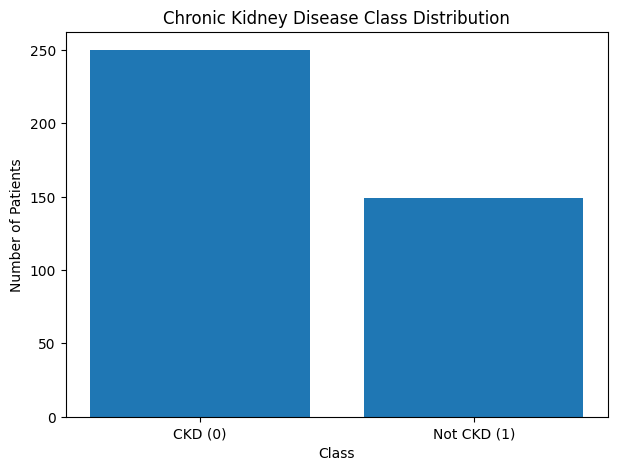

In [30]:
# Step 20: Analyze target class distribution

import matplotlib.pyplot as plt

class_counts = df_encoded["class"].value_counts().sort_index()

print("Target Class Distribution:")
print(class_counts)

print("\nClass Percentages:")
print((class_counts / len(df_encoded) * 100).round(2))

# Plot class distribution
plt.figure(figsize=(7, 5))

plt.bar(
    ["CKD (0)", "Not CKD (1)"],
    class_counts.values
)

plt.xlabel("Class")
plt.ylabel("Number of Patients")
plt.title("Chronic Kidney Disease Class Distribution")

plt.show()

In [31]:
# Step 21: Statistical summary of numerical features

numerical_summary = df_encoded[numerical_features].describe().T

print("Statistical Summary of Numerical Features:")
display(numerical_summary)

Statistical Summary of Numerical Features:


,count,mean,std,min,25%,50%,75%,max
age,399.0,51.492481,16.961416,2.000,42.000,54.50,64.00,90.000
bp,399.0,76.591479,13.502690,50.000,70.000,80.00,80.00,180.000
sg,399.0,1.017707,0.005440,1.005,1.015,1.02,1.02,1.025
al,399.0,0.902256,1.314003,0.000,0.000,0.00,2.00,5.000
su,399.0,0.395990,1.041155,0.000,0.000,0.00,0.00,5.000
bgr,399.0,145.157895,75.331046,22.000,101.000,121.00,150.00,490.000
bu,399.0,56.714787,49.455349,1.500,27.000,42.00,62.50,391.000
sc,399.0,3.002632,5.634874,0.400,0.900,1.30,2.75,76.000
sod,399.0,137.615288,9.212347,4.500,135.000,138.00,141.00,163.000
pot,399.0,4.579950,2.824382,2.500,4.000,4.40,4.80,47.000


In [32]:
# Step 22: Analyze categorical feature distributions

print("Categorical Feature Distributions:\n")

for feature in categorical_features:
    print("=" * 50)
    print(f"Feature: {feature}")
    print(df_encoded[feature].value_counts().sort_index())

Categorical Feature Distributions:

Feature: rbc
rbc
0     47
1    352
Name: count, dtype: int64
Feature: pc
pc
0     76
1    323
Name: count, dtype: int64
Feature: pcc
pcc
0    357
1     42
Name: count, dtype: int64
Feature: ba
ba
0    377
1     22
Name: count, dtype: int64
Feature: htn
htn
0    252
1    147
Name: count, dtype: int64
Feature: dm
dm
0      3
1      2
2    259
3    135
Name: count, dtype: int64
Feature: cad
cad
0      2
1    363
2     34
Name: count, dtype: int64
Feature: appet
appet
0    317
1     82
Name: count, dtype: int64
Feature: pe
pe
0    323
1     76
Name: count, dtype: int64
Feature: ane
ane
0    339
1     60
Name: count, dtype: int64


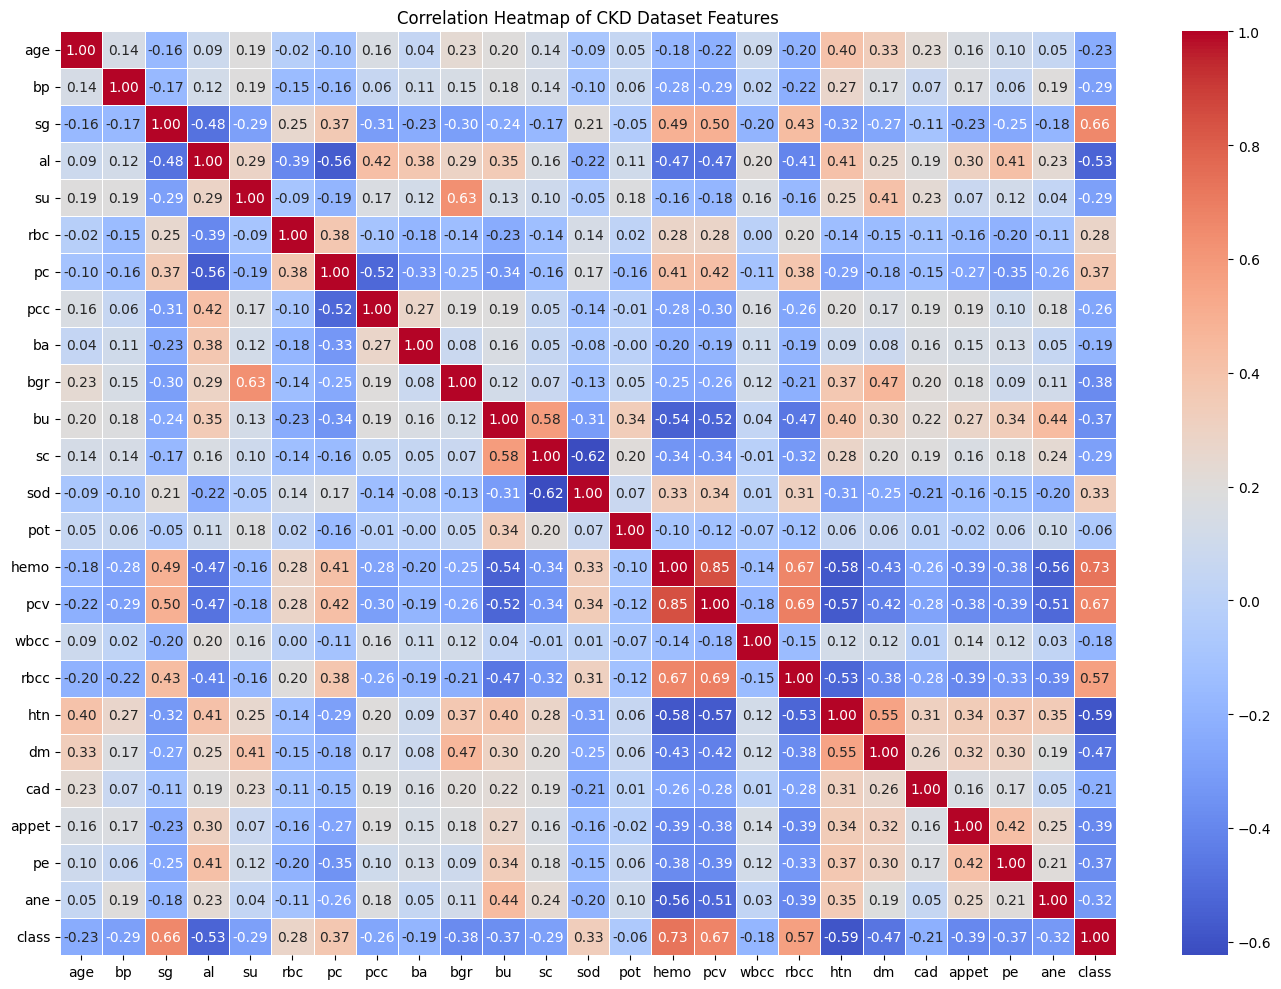

In [33]:
# Step 23: Correlation analysis

import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df_encoded.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of CKD Dataset Features")
plt.tight_layout()
plt.show()

In [34]:
# Step 24: Feature correlation with target

target_correlation = (
    df_encoded.corr(numeric_only=True)["class"]
    .drop("class")
    .sort_values(key=abs, ascending=False)
)

print("Feature Correlation with CKD Target:")
display(target_correlation.to_frame(name="Correlation"))

Feature Correlation with CKD Target:


,Correlation
hemo,0.728101
pcv,0.672395
sg,0.659666
htn,-0.589633
rbcc,0.567113
al,-0.530764
dm,-0.471056
appet,-0.392645
bgr,-0.378595
pc,0.374480


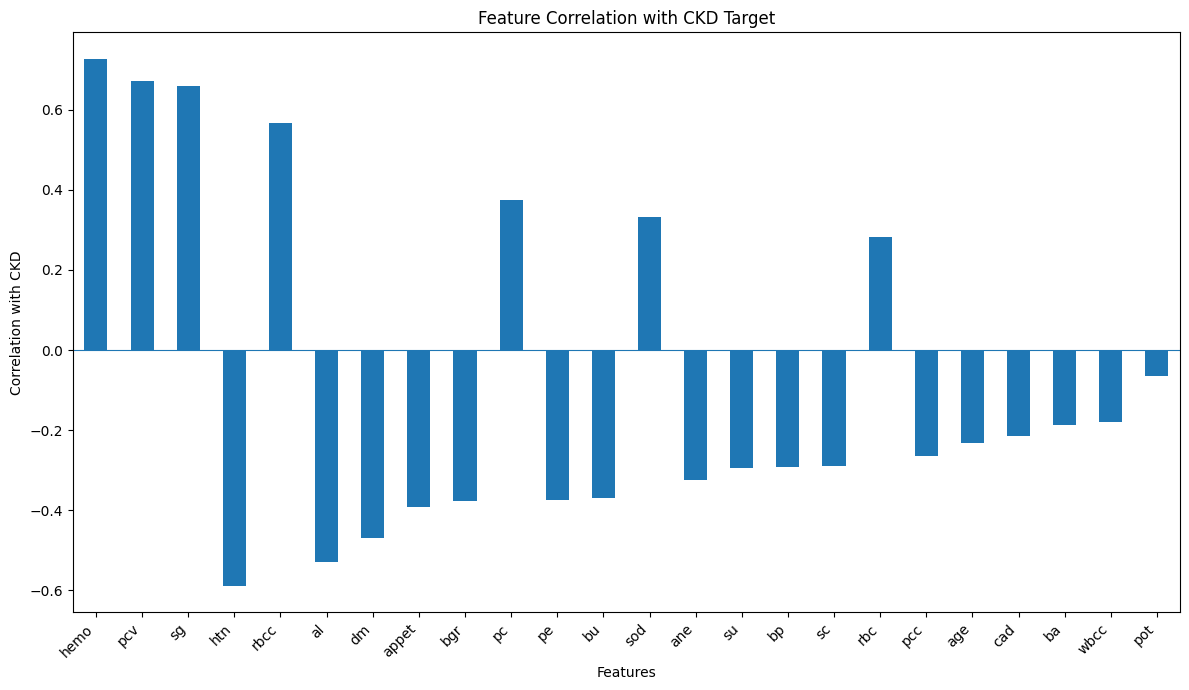

Step 25 completed successfully.

Top 10 features correlated with CKD:
hemo     0.728101
pcv      0.672395
sg       0.659666
htn     -0.589633
rbcc     0.567113
al      -0.530764
dm      -0.471056
appet   -0.392645
bgr     -0.378595
pc       0.374480
Name: class, dtype: float64


In [36]:
# Step 25: Visualize feature correlation with CKD target

import matplotlib.pyplot as plt

# Calculate correlation with the target directly
target_correlation = df_encoded.corr(numeric_only=True)["class"].drop("class")

# Sort by absolute correlation strength
target_correlation_sorted = target_correlation.reindex(
    target_correlation.abs().sort_values(ascending=False).index
)

# Create bar chart
plt.figure(figsize=(12, 7))

target_correlation_sorted.plot(kind="bar")

plt.axhline(y=0, linewidth=0.8)

plt.title("Feature Correlation with CKD Target")
plt.xlabel("Features")
plt.ylabel("Correlation with CKD")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save figure
plt.savefig(
    "../figures/feature_correlation_with_target.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Step 25 completed successfully.")
print("\nTop 10 features correlated with CKD:")
print(target_correlation_sorted.head(10))

In [37]:
# Step 26: Calculate Mutual Information between features and CKD target

from sklearn.feature_selection import mutual_info_classif

# Separate features and target
X = df_encoded.drop("class", axis=1)
y = df_encoded["class"]

# Calculate mutual information
mi_scores = mutual_info_classif(
    X,
    y,
    random_state=42
)

# Create a DataFrame
mi_df = pd.DataFrame({
    "Feature": X.columns,
    "Mutual_Information": mi_scores
})

# Sort from highest to lowest
mi_df = mi_df.sort_values(
    by="Mutual_Information",
    ascending=False
).reset_index(drop=True)

print("Mutual Information Scores:")
display(mi_df)

print("\nTop 10 features:")
display(mi_df.head(10))

Mutual Information Scores:


,Feature,Mutual_Information
0,hemo,0.452485
1,pcv,0.402263
2,sc,0.364440
3,rbcc,0.352964
4,sg,0.308380
5,al,0.229572
6,htn,0.222899
7,sod,0.220204
8,dm,0.204445
9,pot,0.202691



Top 10 features:


,Feature,Mutual_Information
0,hemo,0.452485
1,pcv,0.402263
2,sc,0.364440
3,rbcc,0.352964
4,sg,0.308380
5,al,0.229572
6,htn,0.222899
7,sod,0.220204
8,dm,0.204445
9,pot,0.202691


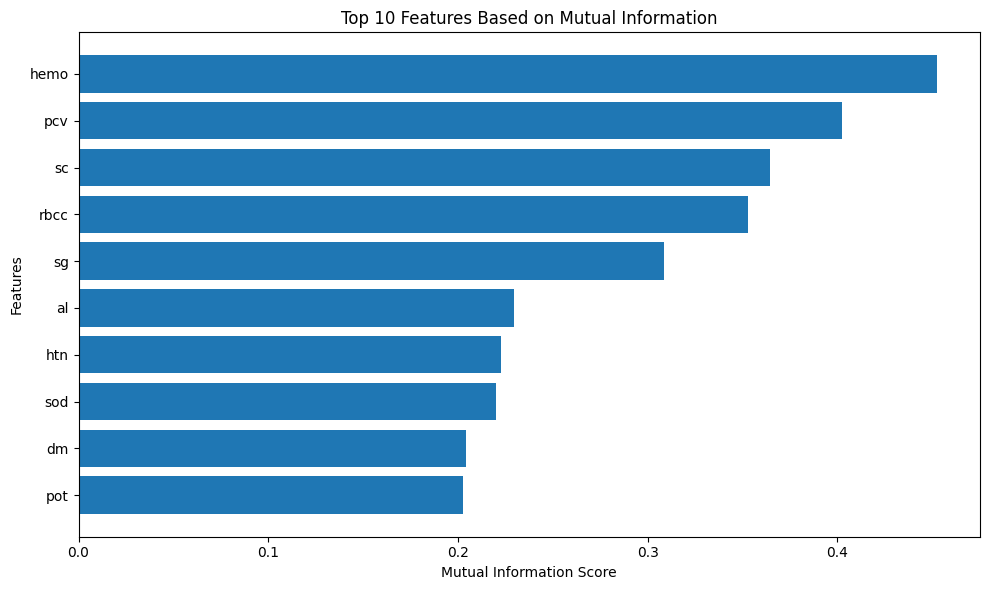

Step 27 completed successfully.
Figure saved: ../figures/mutual_information_features.png


In [38]:
# Step 27: Visualize Mutual Information feature importance

import matplotlib.pyplot as plt

# Select top 10 features
top_mi = mi_df.head(10).sort_values(
    by="Mutual_Information",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_mi["Feature"],
    top_mi["Mutual_Information"]
)

plt.title("Top 10 Features Based on Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()

# Save figure
plt.savefig(
    "../figures/mutual_information_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Step 27 completed successfully.")
print("Figure saved: ../figures/mutual_information_features.png")

In [39]:
# Step 28: Compare Correlation and Mutual Information

# Create correlation DataFrame
correlation_df = target_correlation_sorted.reset_index()

correlation_df.columns = [
    "Feature",
    "Correlation"
]

# Add absolute correlation
correlation_df["Absolute_Correlation"] = (
    correlation_df["Correlation"].abs()
)

# Merge correlation and mutual information
feature_comparison = pd.merge(
    correlation_df,
    mi_df,
    on="Feature",
    how="inner"
)

# Sort by Mutual Information
feature_comparison = feature_comparison.sort_values(
    by="Mutual_Information",
    ascending=False
).reset_index(drop=True)

print("Feature Selection Comparison:")
display(feature_comparison)

print("\nTop 10 features based on Mutual Information:")
display(feature_comparison.head(10))

Feature Selection Comparison:


,Feature,Correlation,Absolute_Correlation,Mutual_Information
0,hemo,0.728101,0.728101,0.452485
1,pcv,0.672395,0.672395,0.402263
2,sc,-0.290644,0.290644,0.364440
3,rbcc,0.567113,0.567113,0.352964
4,sg,0.659666,0.659666,0.308380
5,al,-0.530764,0.530764,0.229572
6,htn,-0.589633,0.589633,0.222899
7,sod,0.333557,0.333557,0.220204
8,dm,-0.471056,0.471056,0.204445
9,pot,-0.064127,0.064127,0.202691



Top 10 features based on Mutual Information:


,Feature,Correlation,Absolute_Correlation,Mutual_Information
0,hemo,0.728101,0.728101,0.452485
1,pcv,0.672395,0.672395,0.402263
2,sc,-0.290644,0.290644,0.364440
3,rbcc,0.567113,0.567113,0.352964
4,sg,0.659666,0.659666,0.308380
5,al,-0.530764,0.530764,0.229572
6,htn,-0.589633,0.589633,0.222899
7,sod,0.333557,0.333557,0.220204
8,dm,-0.471056,0.471056,0.204445
9,pot,-0.064127,0.064127,0.202691


In [40]:
# Step 29: Select candidate features

# Select top 10 features from Mutual Information
mi_features = set(mi_df.head(10)["Feature"])

# Select top 10 features from absolute correlation
correlation_features = set(
    correlation_df.head(10)["Feature"]
)

# Features appearing in both methods
common_features = sorted(
    mi_features.intersection(correlation_features)
)

print("Top 10 Mutual Information features:")
print(sorted(mi_features))

print("\nTop 10 Correlation features:")
print(sorted(correlation_features))

print("\nCommon features selected by both methods:")
print(common_features)

print("\nNumber of common features:", len(common_features))

Top 10 Mutual Information features:
['al', 'dm', 'hemo', 'htn', 'pcv', 'pot', 'rbcc', 'sc', 'sg', 'sod']

Top 10 Correlation features:
['al', 'appet', 'bgr', 'dm', 'hemo', 'htn', 'pc', 'pcv', 'rbcc', 'sg']

Common features selected by both methods:
['al', 'dm', 'hemo', 'htn', 'pcv', 'rbcc', 'sg']

Number of common features: 7


In [41]:
# Step 30: Create candidate-feature dataset

selected_features = common_features

candidate_df = df_encoded[selected_features + ["class"]].copy()

print("Candidate dataset created successfully!")
print("Selected features:")
print(selected_features)

print("\nCandidate dataset shape:")
print(candidate_df.shape)

print("\nCandidate dataset preview:")
display(candidate_df.head())

Candidate dataset created successfully!
Selected features:
['al', 'dm', 'hemo', 'htn', 'pcv', 'rbcc', 'sg']

Candidate dataset shape:
(399, 8)

Candidate dataset preview:


,al,dm,hemo,htn,pcv,rbcc,sg,class
0,1.0,3,15.4,1,44.0,5.2,1.020,0
1,4.0,2,11.3,0,38.0,4.8,1.020,0
2,2.0,3,9.6,0,31.0,4.8,1.010,0
3,4.0,2,11.2,1,32.0,3.9,1.005,0
4,2.0,2,11.6,0,35.0,4.6,1.010,0


In [42]:
# Step 31: Separate features and target

X = candidate_df[selected_features].copy()
y = candidate_df["class"].copy()

print("Features (X) shape:")
print(X.shape)

print("\nTarget (y) shape:")
print(y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features (X) shape:
(399, 7)

Target (y) shape:
(399,)

Feature columns:
['al', 'dm', 'hemo', 'htn', 'pcv', 'rbcc', 'sg']

Target distribution:
class
0    250
1    149
Name: count, dtype: int64


In [43]:
# Step 32: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training feature shape: (319, 7)
Testing feature shape: (80, 7)

Training target distribution:
class
0    200
1    119
Name: count, dtype: int64

Testing target distribution:
class
0    50
1    30
Name: count, dtype: int64


In [44]:
# Step 33: Standardize numerical features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nFirst 5 scaled training rows:")
print(X_train_scaled[:5])

Original training shape: (319, 7)
Scaled training shape: (319, 7)

Original testing shape: (80, 7)
Scaled testing shape: (80, 7)

First 5 scaled training rows:
[[-0.68643817 -0.61108783  0.35167886 -0.73051615  0.3210896   0.14814992
   1.33429222]
 [-0.68643817  1.35797295 -0.10251368 -0.73051615 -0.31908279 -0.09735566
  -0.50035958]
 [-0.68643817  1.35797295 -0.02681492 -0.73051615  0.06502064  0.02539713
  -0.50035958]
 [-0.68643817 -0.61108783  1.63855771 -0.73051615  0.19305512  0.14814992
   0.41696632]
 [-0.68643817 -0.61108783 -0.36745932 -0.73051615 -0.70318622 -0.09735566
  -0.50035958]]


In [45]:
# Step 34: Train Logistic Regression model

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept


In [46]:
# Step 34: Re-train Logistic Regression with a numerically stable solver

from sklearn.linear_model import LogisticRegression
import numpy as np

# Check that scaled data contains only finite values
print("All training values finite:", np.isfinite(X_train_scaled).all())
print("All testing values finite:", np.isfinite(X_test_scaled).all())

# Train Logistic Regression using liblinear
logistic_model = LogisticRegression(
    solver="liblinear",
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

print("\nLogistic Regression retrained successfully.")
print("Coefficient shape:", logistic_model.coef_.shape)
print("Intercept:", logistic_model.intercept_)

All training values finite: True
All testing values finite: True

Logistic Regression retrained successfully.
Coefficient shape: (1, 7)
Intercept: [-3.00480642]


In [47]:
# Step 35: Generate Logistic Regression predictions

# Predict class labels
y_pred_logistic = logistic_model.predict(X_test_scaled)

# Predict probabilities
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 20 predicted classes:")
print(y_pred_logistic[:20])

print("\nFirst 20 predicted probabilities:")
print(y_prob_logistic[:20])

Predictions generated successfully.

First 20 predicted classes:
[0 0 0 0 0 1 0 0 1 1 0 1 0 1 0 1 1 0 0 0]

First 20 predicted probabilities:
[8.04513994e-03 9.43935444e-07 6.28817918e-06 1.05145697e-03
 1.34308838e-06 7.28133444e-01 1.19555425e-01 2.13342369e-05
 9.38306661e-01 8.92323993e-01 1.82015438e-01 9.97916305e-01
 1.86246167e-02 9.50912002e-01 1.16681637e-01 9.77764076e-01
 8.71350632e-01 2.60589424e-04 2.63179119e-09 2.00135408e-03]


In [48]:
# Step 36: Evaluate Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)
roc_auc_logistic = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy : {accuracy_logistic:.4f}")
print(f"Precision: {precision_logistic:.4f}")
print(f"Recall   : {recall_logistic:.4f}")
print(f"F1-Score : {f1_logistic:.4f}")
print(f"ROC-AUC  : {roc_auc_logistic:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["CKD", "Not CKD"]
))

Logistic Regression Performance
--------------------------------
Accuracy : 0.9625
Precision: 0.9655
Recall   : 0.9333
F1-Score : 0.9492
ROC-AUC  : 0.9933

Confusion Matrix:
[[49  1]
 [ 2 28]]

Classification Report:
              precision    recall  f1-score   support

         CKD       0.96      0.98      0.97        50
     Not CKD       0.97      0.93      0.95        30

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80



In [49]:
# Step 37: Train Random Forest

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)

# Generate probability predictions
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully.")
print("Number of trees:", random_forest_model.n_estimators)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

print("\nFirst 20 predicted classes:")
print(y_pred_rf[:20])

print("\nFirst 20 predicted probabilities:")
print(y_prob_rf[:20])


Random Forest trained successfully.
Number of trees: 200
Training samples: 319
Testing samples: 80
Number of features: 7

First 20 predicted classes:
[0 0 0 0 0 1 0 0 1 0 0 1 0 1 0 1 1 0 0 0]

First 20 predicted probabilities:
[0.         0.         0.         0.         0.         0.6344198
 0.005      0.         0.97       0.04348977 0.315      1.
 0.16       1.         0.03       0.99       0.99       0.
 0.         0.        ]


In [50]:
# Step 38: Evaluate Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate performance metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

# Display results
print("Random Forest Performance")
print("-------------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["CKD", "Not CKD"]
))

Random Forest Performance
-------------------------
Accuracy : 0.9750
Precision: 1.0000
Recall   : 0.9333
F1-Score : 0.9655
ROC-AUC  : 0.9987

Confusion Matrix:
[[50  0]
 [ 2 28]]

Classification Report:
              precision    recall  f1-score   support

         CKD       0.96      1.00      0.98        50
     Not CKD       1.00      0.93      0.97        30

    accuracy                           0.97        80
   macro avg       0.98      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



In [52]:
# Step 39: Train XGBoost

from xgboost import XGBClassifier

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
xgb_model.fit(X_train, y_train)

# Generate predictions
y_pred_xgb = xgb_model.predict(X_test)

# Generate probability predictions
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost trained successfully.")
print("Number of trees:", xgb_model.n_estimators)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

print("\nFirst 20 predicted classes:")
print(y_pred_xgb[:20])

print("\nFirst 20 predicted probabilities:")
print(y_prob_xgb[:20])

XGBoost trained successfully.
Number of trees: 200
Training samples: 319
Testing samples: 80
Number of features: 7

First 20 predicted classes:
[0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 1 0 0 0]

First 20 predicted probabilities:
[0.00717521 0.00192048 0.00410178 0.00649041 0.00192048 0.18751106
 0.00432806 0.00649041 0.96534437 0.04030415 0.19082169 0.9936459
 0.28474024 0.98968434 0.04304245 0.969003   0.99192315 0.00344924
 0.00192048 0.00403738]


In [53]:
# Step 40: Evaluate XGBoost

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate performance metrics
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

# Display results
print("XGBoost Performance")
print("-------------------")
print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1-Score : {f1_xgb:.4f}")
print(f"ROC-AUC  : {roc_auc_xgb:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["CKD", "Not CKD"]
))

XGBoost Performance
-------------------
Accuracy : 0.9625
Precision: 1.0000
Recall   : 0.9000
F1-Score : 0.9474
ROC-AUC  : 0.9933

Confusion Matrix:
[[50  0]
 [ 3 27]]

Classification Report:
              precision    recall  f1-score   support

         CKD       0.94      1.00      0.97        50
     Not CKD       1.00      0.90      0.95        30

    accuracy                           0.96        80
   macro avg       0.97      0.95      0.96        80
weighted avg       0.96      0.96      0.96        80



In [54]:
# Step 41: Create Model Comparison Table

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_rf,
        accuracy_xgb
    ],
    "Precision": [
        precision_logistic,
        precision_rf,
        precision_xgb
    ],
    "Recall": [
        recall_logistic,
        recall_rf,
        recall_xgb
    ],
    "F1-Score": [
        f1_logistic,
        f1_rf,
        f1_xgb
    ],
    "ROC-AUC": [
        roc_auc_logistic,
        roc_auc_rf,
        roc_auc_xgb
    ]
})

# Sort models by F1-Score
model_comparison = model_comparison.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("Model Comparison Table")
print("======================")
print(model_comparison.to_string(index=False))

print("\nBest model based on F1-Score:")
print(model_comparison.loc[0, "Model"])

# Save comparison table
model_comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully:")
print("../results/model_comparison.csv")

Model Comparison Table
              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
      Random Forest    0.9750   1.000000 0.933333  0.965517 0.998667
Logistic Regression    0.9625   0.965517 0.933333  0.949153 0.993333
            XGBoost    0.9625   1.000000 0.900000  0.947368 0.993333

Best model based on F1-Score:
Random Forest

Model comparison saved successfully:
../results/model_comparison.csv


In [55]:
# Step 42: 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the three models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

# Store cross-validation results
cv_results = []

for model_name, model in models.items():

    # Logistic Regression requires scaled data
    if model_name == "Logistic Regression":
        X_cv = scaler.transform(X)
    else:
        X_cv = X

    scores = cross_validate(
        model,
        X_cv,
        y,
        cv=cv,
        scoring=["accuracy", "f1", "roc_auc"],
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(),
        "Mean F1-Score": scores["test_f1"].mean(),
        "Std F1-Score": scores["test_f1"].std(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "Std ROC-AUC": scores["test_roc_auc"].std()
    })

# Create results DataFrame
cv_comparison = pd.DataFrame(cv_results)

# Sort by Mean F1-Score
cv_comparison = cv_comparison.sort_values(
    by="Mean F1-Score",
    ascending=False
).reset_index(drop=True)

print("5-Fold Cross-Validation Results")
print("================================")
print(cv_comparison.to_string(index=False))

# Save results
cv_comparison.to_csv(
    "../results/cross_validation_comparison.csv",
    index=False
)

print("\nCross-validation results saved successfully:")
print("../results/cross_validation_comparison.csv")

5-Fold Cross-Validation Results
              Model  Mean Accuracy  Std Accuracy  Mean F1-Score  Std F1-Score  Mean ROC-AUC  Std ROC-AUC
      Random Forest       0.984968      0.009346       0.979753      0.012450      0.999733     0.000533
            XGBoost       0.982437      0.010048       0.976015      0.013915      0.999067     0.001555
Logistic Regression       0.974937      0.007907       0.966953      0.009944      0.997572     0.002275

Cross-validation results saved successfully:
../results/cross_validation_comparison.csv


In [56]:
# Step 43: Select Final Model

# Select Random Forest as the primary model
final_model = random_forest_model

# Store final model information
final_model_name = "Random Forest"

# Extract cross-validation results for Random Forest
rf_cv_row = cv_comparison[
    cv_comparison["Model"] == "Random Forest"
].iloc[0]

# Create final model summary
final_model_summary = {
    "Model": final_model_name,
    "Test Accuracy": accuracy_rf,
    "Test Precision": precision_rf,
    "Test Recall": recall_rf,
    "Test F1-Score": f1_rf,
    "Test ROC-AUC": roc_auc_rf,
    "CV Mean Accuracy": rf_cv_row["Mean Accuracy"],
    "CV Std Accuracy": rf_cv_row["Std Accuracy"],
    "CV Mean F1-Score": rf_cv_row["Mean F1-Score"],
    "CV Std F1-Score": rf_cv_row["Std F1-Score"],
    "CV Mean ROC-AUC": rf_cv_row["Mean ROC-AUC"],
    "CV Std ROC-AUC": rf_cv_row["Std ROC-AUC"]
}

# Convert to DataFrame
final_model_summary_df = pd.DataFrame(
    [final_model_summary]
)

print("Final Model Selection")
print("=====================")
print("Selected Model:", final_model_name)

print("\nFinal Model Performance:")
print(final_model_summary_df.to_string(index=False))

# Save final model summary
final_model_summary_df.to_csv(
    "../results/final_model_summary.csv",
    index=False
)

print("\nFinal model summary saved successfully:")
print("../results/final_model_summary.csv")

Final Model Selection
Selected Model: Random Forest

Final Model Performance:
        Model  Test Accuracy  Test Precision  Test Recall  Test F1-Score  Test ROC-AUC  CV Mean Accuracy  CV Std Accuracy  CV Mean F1-Score  CV Std F1-Score  CV Mean ROC-AUC  CV Std ROC-AUC
Random Forest          0.975             1.0     0.933333       0.965517      0.998667          0.984968         0.009346          0.979753          0.01245         0.999733        0.000533

Final model summary saved successfully:
../results/final_model_summary.csv


In [57]:
# Step 44: Initialize SHAP Explainer for Random Forest

import shap
import numpy as np
import pandas as pd

# Create SHAP Tree Explainer for Random Forest
shap_explainer = shap.TreeExplainer(final_model)

# Calculate SHAP values for the test dataset
shap_values = shap_explainer.shap_values(X_test)

print("SHAP explainer created successfully.")
print("Test dataset shape:", X_test.shape)

# Display SHAP value structure
if isinstance(shap_values, list):
    print("Number of SHAP output classes:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(f"Class {i} SHAP shape:", values.shape)
else:
    print("SHAP values shape:", np.array(shap_values).shape)

# Display feature names
print("\nFeatures used for SHAP:")
print(list(X_test.columns))


SHAP explainer created successfully.
Test dataset shape: (80, 7)
SHAP values shape: (80, 7, 2)

Features used for SHAP:
['al', 'dm', 'hemo', 'htn', 'pcv', 'rbcc', 'sg']


In [58]:
# Step 45: Extract SHAP Values for Not-CKD Class

# SHAP values have shape:
# (samples, features, classes)
# We select Class 1 = Not CKD

shap_values_notckd = shap_values[:, :, 1]

print("SHAP values extracted successfully.")

print("\nSHAP values shape:")
print(shap_values_notckd.shape)

print("\nExpected shape:")
print((X_test.shape[0], X_test.shape[1]))

print("\nFeature names:")
print(list(X_test.columns))

# Create a DataFrame for easier analysis
shap_values_df = pd.DataFrame(
    shap_values_notckd,
    columns=X_test.columns,
    index=X_test.index
)

print("\nFirst 5 rows of SHAP values:")
print(shap_values_df.head())

SHAP values extracted successfully.

SHAP values shape:
(80, 7)

Expected shape:
(80, 7)

Feature names:
['al', 'dm', 'hemo', 'htn', 'pcv', 'rbcc', 'sg']

First 5 rows of SHAP values:
           al        dm      hemo       htn       pcv      rbcc        sg
52   0.017951  0.006600 -0.185971  0.010724 -0.113509 -0.048164 -0.187034
20  -0.068763 -0.054096 -0.098690 -0.076838 -0.057722 -0.027674 -0.115620
87  -0.065550 -0.065701 -0.103678 -0.093235 -0.061042  0.029572 -0.139770
160  0.014853 -0.085629 -0.186770 -0.121981 -0.100893 -0.046923  0.027940
92  -0.070900 -0.053696 -0.098417 -0.076302 -0.057451 -0.027128 -0.115509


In [59]:
# Step 46: Calculate Global SHAP Feature Importance

# Calculate mean absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_values_notckd).mean(axis=0)

# Create feature importance DataFrame
shap_feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

# Sort from most important to least important
shap_feature_importance = shap_feature_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("Global SHAP Feature Importance")
print("==============================")
print(shap_feature_importance.to_string(index=False))

# Save results
shap_feature_importance.to_csv(
    "../results/shap_feature_importance.csv",
    index=False
)

print("\nSHAP feature importance saved successfully:")
print("../results/shap_feature_importance.csv")

Global SHAP Feature Importance
Feature  Mean_Absolute_SHAP
   hemo            0.149940
     sg            0.103507
    pcv            0.095668
    htn            0.062628
     al            0.057209
   rbcc            0.048512
     dm            0.041285

SHAP feature importance saved successfully:
../results/shap_feature_importance.csv


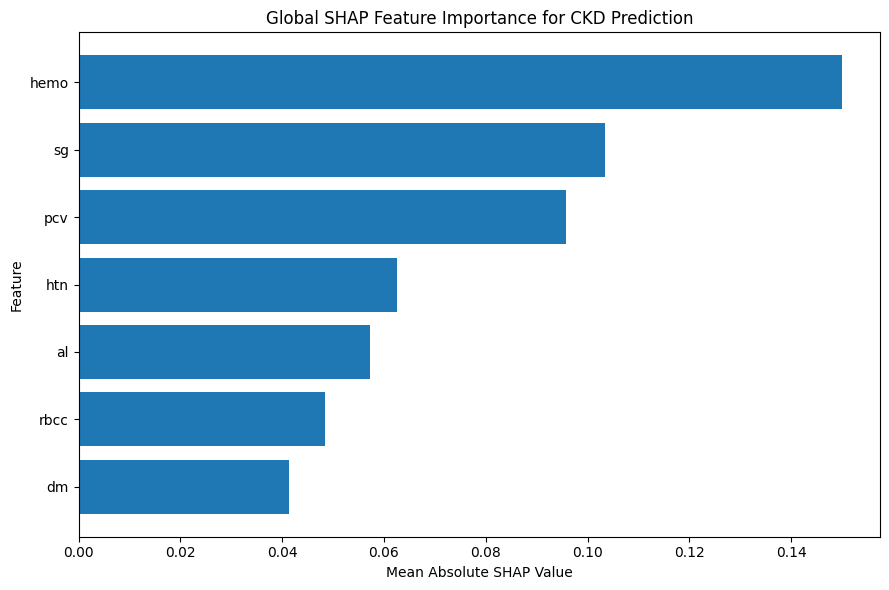

Global SHAP feature importance plot created successfully.
Saved to:
../figures/shap_global_feature_importance.png


In [60]:
# Step 47: Create Global SHAP Feature Importance Plot

import matplotlib.pyplot as plt

# Prepare plotting data
plot_data = shap_feature_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=True
)

# Create figure
plt.figure(figsize=(9, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance for CKD Prediction")

plt.tight_layout()

# Save figure
plt.savefig(
    "../figures/shap_global_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Global SHAP feature importance plot created successfully.")
print("Saved to:")
print("../figures/shap_global_feature_importance.png")

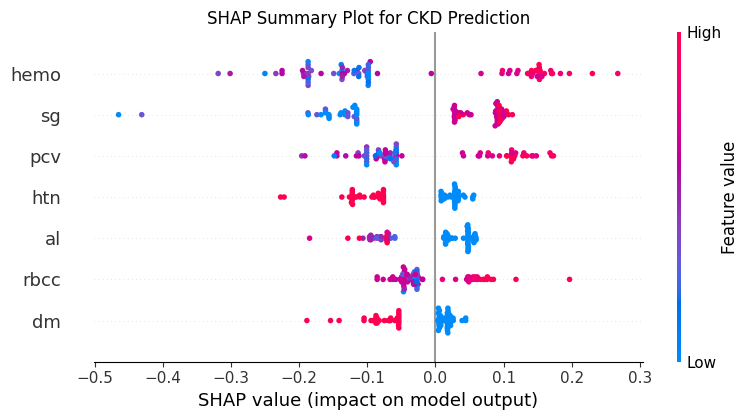

SHAP summary beeswarm plot created successfully.
Saved to:
../figures/shap_summary_beeswarm.png


In [61]:
# Step 48: Create SHAP Summary (Beeswarm) Plot

import matplotlib.pyplot as plt
import shap

# Create SHAP summary plot
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values_notckd,
    X_test,
    feature_names=X_test.columns,
    show=False
)

plt.title("SHAP Summary Plot for CKD Prediction")

plt.tight_layout()

# Save the figure
plt.savefig(
    "../figures/shap_summary_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary beeswarm plot created successfully.")
print("Saved to:")
print("../figures/shap_summary_beeswarm.png")

In [62]:
# Step 49: Analyze Average SHAP Direction

# Calculate average signed SHAP value
mean_signed_shap = shap_values_notckd.mean(axis=0)

# Create SHAP direction DataFrame
shap_direction = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_SHAP": mean_signed_shap,
    "Mean_Absolute_SHAP": np.abs(shap_values_notckd).mean(axis=0)
})

# Sort by absolute importance
shap_direction = shap_direction.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("SHAP Feature Direction Analysis")
print("===============================")
print(shap_direction.to_string(index=False))

# Save results
shap_direction.to_csv(
    "../results/shap_feature_direction.csv",
    index=False
)

print("\nSHAP direction analysis saved successfully:")
print("../results/shap_feature_direction.csv")

SHAP Feature Direction Analysis
Feature  Mean_SHAP  Mean_Absolute_SHAP
   hemo  -0.037898            0.149940
     sg  -0.015895            0.103507
    pcv  -0.013586            0.095668
    htn  -0.033299            0.062628
     al  -0.009985            0.057209
   rbcc  -0.009172            0.048512
     dm  -0.021550            0.041285

SHAP direction analysis saved successfully:
../results/shap_feature_direction.csv


PART 1: DIRECTORIES READY
results/  -> ready
figures/  -> ready
models/   -> ready
app/      -> ready

PART 2: SHAP DIRECTION ANALYSIS


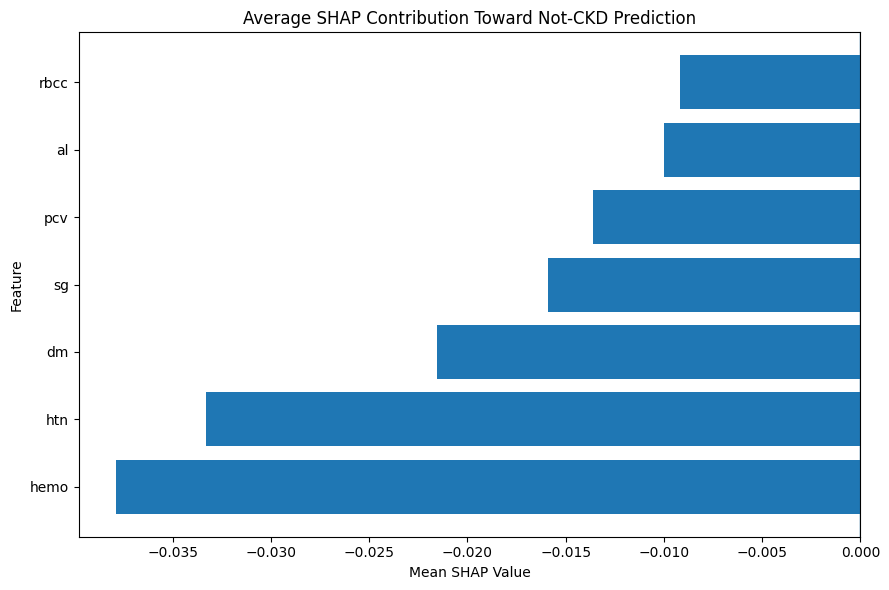

SHAP direction plot saved:
../figures/shap_direction_plot.png

PART 3: SELECT REPRESENTATIVE TEST PATIENT
Representative test patient selected.
Patient index: 365
Actual class: 1
Predicted class: 1
Probability of Not CKD: 0.6344

Patient feature values:
al       0.00
dm       2.00
hemo    12.60
htn      0.00
pcv     40.00
rbcc     6.30
sg       1.02
Name: 365, dtype: float64

PART 4: PATIENT-LEVEL SHAP EXPLANATION
Patient-level SHAP contributions:
Feature  Feature_Value  SHAP_Value  Absolute_SHAP
   rbcc           6.30    0.196727       0.196727
   hemo          12.60   -0.194949       0.194949
    pcv          40.00   -0.115911       0.115911
     sg           1.02    0.097828       0.097828
     al           0.00    0.056162       0.056162
    htn           0.00    0.056116       0.056116
     dm           2.00    0.039044       0.039044

Saved:
../results/representative_patient_shap.csv

PART 5: PATIENT-LEVEL SHAP PLOT


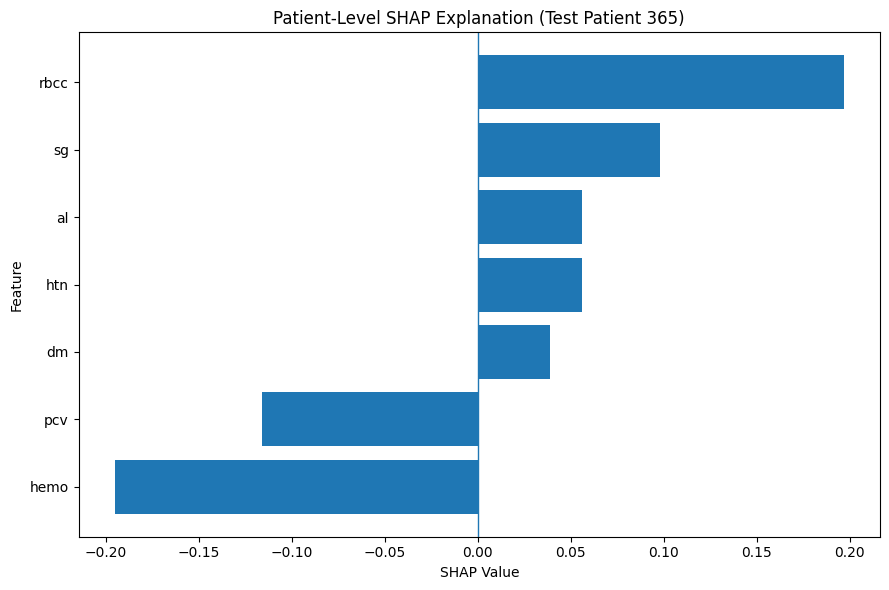

Patient-level SHAP plot saved:
../figures/patient_shap_explanation.png

PART 6: LIME EXPLANATION
LIME explanation generated successfully.

LIME contributions:
Feature  LIME_Contribution  Absolute_LIME
     sg           0.117294       0.117294
   hemo           0.081430       0.081430
     al          -0.069278       0.069278
    pcv           0.058957       0.058957
    htn          -0.048360       0.048360
   rbcc           0.039153       0.039153
     dm          -0.031585       0.031585

Saved:
../results/representative_patient_lime.csv

PART 7: LIME VISUALIZATION


/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/Users/parasjain/Desktop/Explainable_Disease_Prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ +

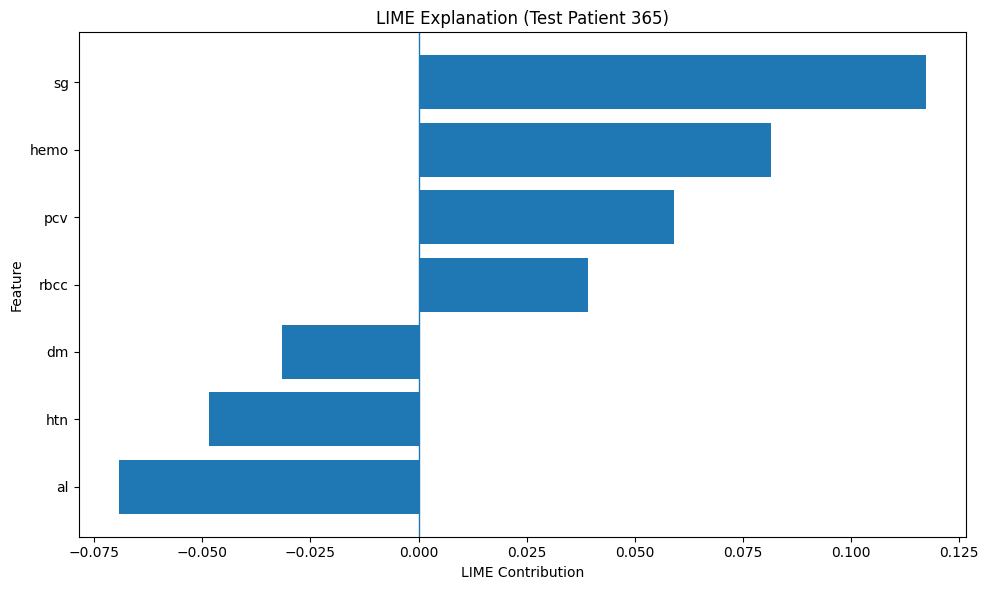

LIME plot saved:
../figures/patient_lime_explanation.png

PART 8: SHAP + LIME COMPARISON
SHAP + LIME comparison:
Feature  SHAP_Value  LIME_Contribution  Same_Direction
     al    0.056162          -0.069278           False
     dm    0.039044          -0.031585           False
   hemo   -0.194949           0.081430           False
    htn    0.056116          -0.048360           False
    pcv   -0.115911           0.058957           False
   rbcc    0.196727           0.039153            True
     sg    0.097828           0.117294            True

Saved:
../results/shap_lime_comparison.csv

PART 9: SAVE FINAL MODEL
Random Forest model saved:
../models/random_forest_ckd_model.joblib
Model metadata saved:
../models/model_metadata.json
Representative patient summary saved:
../results/representative_patient_summary.json
XAI summary saved:
../results/xai_summary.json

PART 13: CREATE STREAMLIT APPLICATION
Streamlit application created:
../app/app.py

FINAL PROJECT ARTIFACT CHECK
✓ ../result

In [64]:
# ============================================================
# MASTER BLOCK
# COMPLETE XAI + MODEL SAVING + STREAMLIT SETUP
# Explainable Machine Learning Framework for Early CKD Prediction
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from lime.lime_tabular import LimeTabularExplainer

# ============================================================
# PART 1 — CREATE REQUIRED DIRECTORIES
# ============================================================

os.makedirs("../results", exist_ok=True)
os.makedirs("../figures", exist_ok=True)
os.makedirs("../models", exist_ok=True)
os.makedirs("../app", exist_ok=True)

print("=" * 70)
print("PART 1: DIRECTORIES READY")
print("=" * 70)

print("results/  -> ready")
print("figures/  -> ready")
print("models/   -> ready")
print("app/      -> ready")


# ============================================================
# PART 2 — SHAP DIRECTION PLOT
# ============================================================

print("\n" + "=" * 70)
print("PART 2: SHAP DIRECTION ANALYSIS")
print("=" * 70)

direction_plot_data = shap_direction.sort_values(
    by="Mean_SHAP",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    direction_plot_data["Feature"],
    direction_plot_data["Mean_SHAP"]
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("Mean SHAP Value")
plt.ylabel("Feature")
plt.title("Average SHAP Contribution Toward Not-CKD Prediction")

plt.tight_layout()

plt.savefig(
    "../figures/shap_direction_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP direction plot saved:")
print("../figures/shap_direction_plot.png")


# ============================================================
# PART 3 — SELECT A REPRESENTATIVE PATIENT
# ============================================================
#
# We select the test patient whose predicted probability
# is closest to 0.50.
#
# This is useful because the model is least certain about
# this patient, making the explanation especially informative.
# ============================================================

print("\n" + "=" * 70)
print("PART 3: SELECT REPRESENTATIVE TEST PATIENT")
print("=" * 70)

# Find the test patient closest to the decision boundary
representative_position = np.argmin(
    np.abs(y_prob_rf - 0.50)
)

representative_index = X_test.index[representative_position]

representative_patient = X_test.iloc[
    representative_position
].copy()

representative_actual = y_test.iloc[
    representative_position
]

representative_prediction = y_pred_rf[
    representative_position
]

representative_probability = y_prob_rf[
    representative_position
]

print("Representative test patient selected.")
print("Patient index:", representative_index)
print("Actual class:", representative_actual)
print("Predicted class:", representative_prediction)
print("Probability of Not CKD:", round(
    representative_probability, 4
))

print("\nPatient feature values:")
print(representative_patient)


# ============================================================
# PART 4 — PATIENT-LEVEL SHAP EXPLANATION
# ============================================================

print("\n" + "=" * 70)
print("PART 4: PATIENT-LEVEL SHAP EXPLANATION")
print("=" * 70)

# Extract SHAP values for the representative patient
patient_shap_values = shap_values_notckd[
    representative_position
]

patient_shap_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Feature_Value": representative_patient.values,
    "SHAP_Value": patient_shap_values,
    "Absolute_SHAP": np.abs(patient_shap_values)
})

patient_shap_df = patient_shap_df.sort_values(
    by="Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("Patient-level SHAP contributions:")
print(patient_shap_df.to_string(index=False))

# Save patient-level SHAP values
patient_shap_df.to_csv(
    "../results/representative_patient_shap.csv",
    index=False
)

print("\nSaved:")
print("../results/representative_patient_shap.csv")


# ============================================================
# PART 5 — PATIENT SHAP BAR PLOT
# ============================================================

print("\n" + "=" * 70)
print("PART 5: PATIENT-LEVEL SHAP PLOT")
print("=" * 70)

patient_plot_data = patient_shap_df.sort_values(
    by="SHAP_Value",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    patient_plot_data["Feature"],
    patient_plot_data["SHAP_Value"]
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("SHAP Value")
plt.ylabel("Feature")
plt.title(
    f"Patient-Level SHAP Explanation "
    f"(Test Patient {representative_index})"
)

plt.tight_layout()

plt.savefig(
    "../figures/patient_shap_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Patient-level SHAP plot saved:")
print("../figures/patient_shap_explanation.png")


# ============================================================
# PART 6 — LIME EXPLAINABILITY
# ============================================================

print("\n" + "=" * 70)
print("PART 6: LIME EXPLANATION")
print("=" * 70)

# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X_train.columns),
    class_names=["CKD", "Not CKD"],
    mode="classification",
    discretize_continuous=False,
    random_state=42
)

# Create LIME explanation
lime_explanation = lime_explainer.explain_instance(
    representative_patient.values,
    final_model.predict_proba,
    num_features=len(X_test.columns)
)

# Extract LIME contributions
lime_list = lime_explanation.as_list(
    label=1
)

lime_df = pd.DataFrame(
    lime_list,
    columns=["Feature", "LIME_Contribution"]
)

lime_df["Absolute_LIME"] = np.abs(
    lime_df["LIME_Contribution"]
)

lime_df = lime_df.sort_values(
    by="Absolute_LIME",
    ascending=False
).reset_index(drop=True)

print("LIME explanation generated successfully.")
print("\nLIME contributions:")
print(lime_df.to_string(index=False))

# Save LIME results
lime_df.to_csv(
    "../results/representative_patient_lime.csv",
    index=False
)

print("\nSaved:")
print("../results/representative_patient_lime.csv")


# ============================================================
# PART 7 — LIME VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("PART 7: LIME VISUALIZATION")
print("=" * 70)

lime_plot_data = lime_df.sort_values(
    by="LIME_Contribution",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    lime_plot_data["Feature"],
    lime_plot_data["LIME_Contribution"]
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("LIME Contribution")
plt.ylabel("Feature")
plt.title(
    f"LIME Explanation "
    f"(Test Patient {representative_index})"
)

plt.tight_layout()

plt.savefig(
    "../figures/patient_lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("LIME plot saved:")
print("../figures/patient_lime_explanation.png")


# ============================================================
# PART 8 — SHAP + LIME COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("PART 8: SHAP + LIME COMPARISON")
print("=" * 70)

# Prepare SHAP comparison table
shap_compare = patient_shap_df[
    ["Feature", "SHAP_Value"]
].copy()

# Merge with LIME results
explainability_comparison = shap_compare.merge(
    lime_df[["Feature", "LIME_Contribution"]],
    on="Feature",
    how="outer"
)

# Fill missing values if necessary
explainability_comparison = (
    explainability_comparison.fillna(0)
)

# Calculate whether SHAP and LIME agree in direction
explainability_comparison["Same_Direction"] = (
    np.sign(
        explainability_comparison["SHAP_Value"]
    )
    ==
    np.sign(
        explainability_comparison["LIME_Contribution"]
    )
)

print("SHAP + LIME comparison:")
print(
    explainability_comparison.to_string(
        index=False
    )
)

# Save comparison
explainability_comparison.to_csv(
    "../results/shap_lime_comparison.csv",
    index=False
)

print("\nSaved:")
print("../results/shap_lime_comparison.csv")


# ============================================================
# PART 9 — SAVE FINAL RANDOM FOREST MODEL
# ============================================================

print("\n" + "=" * 70)
print("PART 9: SAVE FINAL MODEL")
print("=" * 70)

# Save Random Forest
joblib.dump(
    final_model,
    "../models/random_forest_ckd_model.joblib"
)

print("Random Forest model saved:")
print("../models/random_forest_ckd_model.joblib")


# ============================================================
# PART 10 — SAVE FEATURE INFORMATION
# ============================================================

feature_information = {
    "selected_features": list(selected_features),
    "target_column": "class",
    "class_mapping": {
        "0": "CKD",
        "1": "Not CKD"
    },
    "final_model": "Random Forest"
}

with open(
    "../models/model_metadata.json",
    "w"
) as f:
    json.dump(
        feature_information,
        f,
        indent=4
    )

print("Model metadata saved:")
print("../models/model_metadata.json")


# ============================================================
# PART 11 — SAVE REPRESENTATIVE PATIENT SUMMARY
# ============================================================

patient_summary = {
    "patient_index": int(representative_index),
    "actual_class": (
        "CKD"
        if representative_actual == 0
        else "Not CKD"
    ),
    "predicted_class": (
        "CKD"
        if representative_prediction == 0
        else "Not CKD"
    ),
    "probability_not_ckd": float(
        representative_probability
    ),
    "probability_ckd": float(
        1 - representative_probability
    )
}

with open(
    "../results/representative_patient_summary.json",
    "w"
) as f:
    json.dump(
        patient_summary,
        f,
        indent=4
    )

print("Representative patient summary saved:")
print("../results/representative_patient_summary.json")


# ============================================================
# PART 12 — CREATE FINAL XAI SUMMARY
# ============================================================

top_shap_feature = shap_feature_importance.iloc[0]["Feature"]

xai_summary = {
    "final_model": "Random Forest",
    "number_of_test_patients": int(len(X_test)),
    "number_of_features": int(len(selected_features)),
    "top_global_shap_feature": top_shap_feature,
    "global_shap_features": list(
        shap_feature_importance["Feature"]
    ),
    "xai_methods": [
        "SHAP",
        "LIME"
    ],
    "representative_patient_index": int(
        representative_index
    ),
    "test_accuracy": float(accuracy_rf),
    "test_f1_score": float(f1_rf),
    "test_roc_auc": float(roc_auc_rf),
    "cv_mean_accuracy": float(
        rf_cv_row["Mean Accuracy"]
    ),
    "cv_mean_f1_score": float(
        rf_cv_row["Mean F1-Score"]
    ),
    "cv_mean_roc_auc": float(
        rf_cv_row["Mean ROC-AUC"]
    )
}

with open(
    "../results/xai_summary.json",
    "w"
) as f:
    json.dump(
        xai_summary,
        f,
        indent=4
    )

print("XAI summary saved:")
print("../results/xai_summary.json")


# ============================================================
# PART 13 — CREATE STREAMLIT APPLICATION
# ============================================================

print("\n" + "=" * 70)
print("PART 13: CREATE STREAMLIT APPLICATION")
print("=" * 70)

streamlit_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import shap

from lime.lime_tabular import LimeTabularExplainer


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Explainable CKD Prediction",
    page_icon="🩺",
    layout="wide"
)


# ============================================================
# LOAD MODEL
# ============================================================

MODEL_PATH = "../models/random_forest_ckd_model.joblib"

model = joblib.load(MODEL_PATH)

FEATURES = [
    "al",
    "dm",
    "hemo",
    "htn",
    "pcv",
    "rbcc",
    "sg"
]


# ============================================================
# APPLICATION TITLE
# ============================================================

st.title("Explainable Chronic Kidney Disease Prediction")

st.write(
    """
    This research prototype predicts the likelihood of Chronic Kidney
    Disease (CKD) using a Random Forest model and provides explanations
    using SHAP and LIME.
    """
)

st.warning(
    "Research prototype only. This system is not a medical diagnosis "
    "and should not replace professional medical evaluation."
)


# ============================================================
# INPUT SECTION
# ============================================================

st.header("Patient Information")

col1, col2 = st.columns(2)

with col1:

    al = st.number_input(
        "Albumin (al)",
        min_value=0.0,
        max_value=5.0,
        value=1.0,
        step=1.0
    )

    dm = st.selectbox(
        "Diabetes Mellitus (dm)",
        options=[0, 1],
        format_func=lambda x:
            "No / 0" if x == 0 else "Yes / 1"
    )

    hemo = st.number_input(
        "Hemoglobin (hemo)",
        min_value=3.0,
        max_value=20.0,
        value=12.0,
        step=0.1
    )

    htn = st.selectbox(
        "Hypertension (htn)",
        options=[0, 1],
        format_func=lambda x:
            "No / 0" if x == 0 else "Yes / 1"
    )


with col2:

    pcv = st.number_input(
        "Packed Cell Volume (pcv)",
        min_value=10.0,
        max_value=60.0,
        value=40.0,
        step=1.0
    )

    rbcc = st.number_input(
        "Red Blood Cell Count (rbcc)",
        min_value=2.0,
        max_value=10.0,
        value=4.5,
        step=0.1
    )

    sg = st.number_input(
        "Specific Gravity (sg)",
        min_value=1.000,
        max_value=1.030,
        value=1.020,
        step=0.001,
        format="%.3f"
    )


# ============================================================
# CREATE INPUT DATAFRAME
# ============================================================

input_data = pd.DataFrame(
    [[
        al,
        dm,
        hemo,
        htn,
        pcv,
        rbcc,
        sg
    ]],
    columns=FEATURES
)


# ============================================================
# PREDICTION
# ============================================================

if st.button(
    "Predict CKD",
    type="primary"
):

    probability = model.predict_proba(
        input_data
    )[0]

    prediction = model.predict(
        input_data
    )[0]

    ckd_probability = probability[0]
    not_ckd_probability = probability[1]

    st.header("Prediction Result")

    if prediction == 0:
        st.error(
            f"Prediction: CKD\n\n"
            f"Model probability: "
            f"{ckd_probability:.2%}"
        )
    else:
        st.success(
            f"Prediction: Not CKD\n\n"
            f"Model probability: "
            f"{not_ckd_probability:.2%}"
        )

    # ========================================================
    # SHAP EXPLANATION
    # ========================================================

    st.header("SHAP Explanation")

    try:

        explainer = shap.TreeExplainer(
            model
        )

        shap_result = explainer.shap_values(
            input_data
        )

        if isinstance(
            shap_result,
            list
        ):

            patient_shap = np.array(
                shap_result[1][0]
            )

        else:

            shap_array = np.array(
                shap_result
            )

            if shap_array.ndim == 3:
                patient_shap = shap_array[
                    0, :, 1
                ]
            elif shap_array.ndim == 2:
                patient_shap = shap_array[
                    0
                ]
            else:
                patient_shap = shap_array

        shap_df = pd.DataFrame({
            "Feature": FEATURES,
            "SHAP Value": patient_shap
        })

        shap_df = shap_df.sort_values(
            by="SHAP Value",
            ascending=True
        )

        st.bar_chart(
            shap_df.set_index(
                "Feature"
            )
        )

        st.dataframe(
            shap_df,
            use_container_width=True
        )

    except Exception as e:

        st.warning(
            f"SHAP explanation could not be generated: {e}"
        )


    # ========================================================
    # IMPORTANT NOTE
    # ========================================================

    st.info(
        """
        SHAP values describe how the model's features contribute to
        its prediction. They represent model behavior and should not
        be interpreted as causal medical effects.
        """
    )
'''

with open(
    "../app/app.py",
    "w"
) as f:
    f.write(streamlit_code)

print("Streamlit application created:")
print("../app/app.py")


# ============================================================
# PART 14 — FINAL FILE CHECK
# ============================================================

print("\n" + "=" * 70)
print("FINAL PROJECT ARTIFACT CHECK")
print("=" * 70)

required_files = [
    "../results/model_comparison.csv",
    "../results/cross_validation_comparison.csv",
    "../results/final_model_summary.csv",
    "../results/shap_feature_importance.csv",
    "../results/shap_feature_direction.csv",
    "../results/representative_patient_shap.csv",
    "../results/representative_patient_lime.csv",
    "../results/shap_lime_comparison.csv",
    "../results/representative_patient_summary.json",
    "../results/xai_summary.json",
    "../figures/shap_global_feature_importance.png",
    "../figures/shap_summary_beeswarm.png",
    "../figures/shap_direction_plot.png",
    "../figures/patient_shap_explanation.png",
    "../figures/patient_lime_explanation.png",
    "../models/random_forest_ckd_model.joblib",
    "../models/model_metadata.json",
    "../app/app.py"
]

successful_files = 0

for file_path in required_files:

    if os.path.exists(file_path):

        print("✓", file_path)
        successful_files += 1

    else:

        print("✗ MISSING:", file_path)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("MASTER XAI PIPELINE COMPLETED")
print("=" * 70)

print(f"""
Final Model:
Random Forest

Test Accuracy:
{accuracy_rf:.4f}

Test F1-Score:
{f1_rf:.4f}

Test ROC-AUC:
{roc_auc_rf:.4f}

5-Fold Mean Accuracy:
{rf_cv_row["Mean Accuracy"]:.4f}

5-Fold Mean F1-Score:
{rf_cv_row["Mean F1-Score"]:.4f}

5-Fold Mean ROC-AUC:
{rf_cv_row["Mean ROC-AUC"]:.4f}

Top Global SHAP Feature:
{top_shap_feature}

XAI Methods:
SHAP + LIME

Artifacts successfully created:
{successful_files}/{len(required_files)}
""")

print("=" * 70)
print("NEXT MAJOR PHASE: STREAMLIT TESTING + REVIEW 1 PREPARATION")
print("=" * 70)

In [65]:
# Step 51A: Fix Streamlit Model Path

from pathlib import Path

app_path = Path("../app/app.py")

app_code = app_path.read_text()

# Add os import
app_code = app_code.replace(
    "import streamlit as st",
    "import os\nimport streamlit as st"
)

# Replace relative model path with a robust absolute path
app_code = app_code.replace(
    'MODEL_PATH = "../models/random_forest_ckd_model.joblib"',
    'BASE_DIR = os.path.dirname(os.path.abspath(__file__))\n'
    'MODEL_PATH = os.path.join(BASE_DIR, "..", "models", "random_forest_ckd_model.joblib")'
)

app_path.write_text(app_code)

print("Streamlit application path fixed successfully.")
print("Application file:")
print(app_path.resolve())

print("\nModel file exists:",
      Path("../models/random_forest_ckd_model.joblib").exists())

print("App file exists:",
      app_path.exists())

Streamlit application path fixed successfully.
Application file:
/Users/parasjain/Desktop/Explainable_Disease_Prediction/app/app.py

Model file exists: True
App file exists: True


In [66]:
# ============================================================
# STEP 52 — FIX STREAMLIT XAI
# Correct class-specific SHAP + LIME explanations
# ============================================================

from pathlib import Path

app_path = Path("../app/app.py")

streamlit_code = r'''
import os
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import shap

from lime.lime_tabular import LimeTabularExplainer


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Explainable CKD Prediction",
    page_icon="🩺",
    layout="wide"
)


# ============================================================
# LOAD MODEL
# ============================================================

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(
    BASE_DIR,
    "..",
    "models",
    "random_forest_ckd_model.joblib"
)

model = joblib.load(MODEL_PATH)


# ============================================================
# FEATURE DEFINITIONS
# ============================================================

FEATURES = [
    "al",
    "dm",
    "hemo",
    "htn",
    "pcv",
    "rbcc",
    "sg"
]

FEATURE_LABELS = {
    "al": "Albumin (al)",
    "dm": "Diabetes Mellitus (dm)",
    "hemo": "Hemoglobin (hemo)",
    "htn": "Hypertension (htn)",
    "pcv": "Packed Cell Volume (pcv)",
    "rbcc": "Red Blood Cell Count (rbcc)",
    "sg": "Specific Gravity (sg)"
}


# ============================================================
# PAGE TITLE
# ============================================================

st.title(
    "Explainable Chronic Kidney Disease Prediction"
)

st.write(
    """
    This research prototype predicts the likelihood of Chronic Kidney
    Disease (CKD) using a Random Forest model and provides
    patient-level explanations using SHAP and LIME.
    """
)

st.warning(
    """
    Research prototype only. This system is not a medical diagnosis
    and should not replace professional medical evaluation.
    """
)


# ============================================================
# PATIENT INPUT
# ============================================================

st.header("Patient Information")

col1, col2 = st.columns(2)

with col1:

    al = st.number_input(
        "Albumin (al)",
        min_value=0.0,
        max_value=5.0,
        value=1.0,
        step=1.0
    )

    dm = st.selectbox(
        "Diabetes Mellitus (dm)",
        options=[0, 1],
        format_func=lambda x:
            "No / 0" if x == 0 else "Yes / 1"
    )

    hemo = st.number_input(
        "Hemoglobin (hemo)",
        min_value=3.0,
        max_value=20.0,
        value=12.0,
        step=0.1
    )

    htn = st.selectbox(
        "Hypertension (htn)",
        options=[0, 1],
        format_func=lambda x:
            "No / 0" if x == 0 else "Yes / 1"
    )


with col2:

    pcv = st.number_input(
        "Packed Cell Volume (pcv)",
        min_value=10.0,
        max_value=60.0,
        value=40.0,
        step=1.0
    )

    rbcc = st.number_input(
        "Red Blood Cell Count (rbcc)",
        min_value=2.0,
        max_value=10.0,
        value=4.5,
        step=0.1
    )

    sg = st.number_input(
        "Specific Gravity (sg)",
        min_value=1.000,
        max_value=1.030,
        value=1.020,
        step=0.001,
        format="%.3f"
    )


# ============================================================
# INPUT DATAFRAME
# ============================================================

input_data = pd.DataFrame(
    [[
        al,
        dm,
        hemo,
        htn,
        pcv,
        rbcc,
        sg
    ]],
    columns=FEATURES
)


# ============================================================
# PREDICTION
# ============================================================

if st.button(
    "Predict CKD",
    type="primary"
):

    # --------------------------------------------------------
    # Model prediction
    # --------------------------------------------------------

    prediction = int(
        model.predict(input_data)[0]
    )

    probabilities = model.predict_proba(
        input_data
    )[0]

    ckd_probability = float(
        probabilities[0]
    )

    not_ckd_probability = float(
        probabilities[1]
    )


    # --------------------------------------------------------
    # Prediction result
    # --------------------------------------------------------

    st.header("Prediction Result")

    result_col1, result_col2 = st.columns(2)

    with result_col1:

        if prediction == 0:

            st.error(
                f"Prediction: CKD"
            )

        else:

            st.success(
                f"Prediction: Not CKD"
            )


    with result_col2:

        if prediction == 0:

            st.metric(
                "CKD Probability",
                f"{ckd_probability:.2%}"
            )

        else:

            st.metric(
                "Not CKD Probability",
                f"{not_ckd_probability:.2%}"
            )


    # Display both probabilities
    st.subheader("Model Probabilities")

    probability_df = pd.DataFrame({
        "Class": [
            "CKD",
            "Not CKD"
        ],
        "Probability": [
            ckd_probability,
            not_ckd_probability
        ]
    })

    st.dataframe(
        probability_df,
        use_container_width=True,
        hide_index=True
    )


    # ========================================================
    # SHAP EXPLANATION
    # ========================================================

    st.header("SHAP Explanation")

    st.write(
        f"""
        The SHAP explanation below corresponds to the model's
        predicted class: **{"CKD" if prediction == 0 else "Not CKD"}**.
        """
    )

    try:

        shap_explainer = shap.TreeExplainer(
            model
        )

        shap_result = shap_explainer.shap_values(
            input_data
        )

        shap_array = np.array(
            shap_result
        )

        # ----------------------------------------------------
        # Handle SHAP output for binary classification
        # ----------------------------------------------------

        if isinstance(shap_result, list):

            # Older SHAP format:
            # [class_0_values, class_1_values]

            predicted_shap = np.array(
                shap_result[prediction][0]
            )

        elif shap_array.ndim == 3:

            # New SHAP format:
            # samples × features × classes

            predicted_shap = shap_array[
                0,
                :,
                prediction
            ]

        elif shap_array.ndim == 2:

            predicted_shap = shap_array[
                0
            ]

        else:

            predicted_shap = shap_array


        # ----------------------------------------------------
        # SHAP DataFrame
        # ----------------------------------------------------

        shap_df = pd.DataFrame({
            "Feature": FEATURES,
            "Feature Value": input_data.iloc[0].values,
            "SHAP Value": predicted_shap
        })

        shap_df["Absolute SHAP"] = np.abs(
            shap_df["SHAP Value"]
        )

        shap_df = shap_df.sort_values(
            by="Absolute SHAP",
            ascending=False
        ).reset_index(drop=True)


        # ----------------------------------------------------
        # Display SHAP table
        # ----------------------------------------------------

        display_shap = shap_df.copy()

        display_shap["Feature"] = (
            display_shap["Feature"]
            .map(FEATURE_LABELS)
        )

        st.dataframe(
            display_shap,
            use_container_width=True,
            hide_index=True
        )


        # ----------------------------------------------------
        # SHAP chart
        # ----------------------------------------------------

        chart_data = shap_df[
            ["Feature", "SHAP Value"]
        ].copy()

        chart_data["Feature"] = (
            chart_data["Feature"]
            .map(FEATURE_LABELS)
        )

        chart_data = chart_data.set_index(
            "Feature"
        )

        st.bar_chart(
            chart_data
        )


    except Exception as e:

        st.error(
            f"SHAP explanation could not be generated: {e}"
        )


    # ========================================================
    # LIME EXPLANATION
    # ========================================================

    st.header("LIME Explanation")

    st.write(
        f"""
        LIME provides a local explanation of the same patient
        prediction using a locally approximated model.
        Predicted class: **{"CKD" if prediction == 0 else "Not CKD"}**
        """
    )

    try:

        # ----------------------------------------------------
        # Load processed training data
        # ----------------------------------------------------

        processed_data_path = os.path.join(
            BASE_DIR,
            "..",
            "data",
            "processed",
            "ckd_processed.csv"
        )

        processed_df = pd.read_csv(
            processed_data_path
        )

        X_training = processed_df[
            FEATURES
        ]

        # ----------------------------------------------------
        # Create LIME explainer
        # ----------------------------------------------------

        lime_explainer = LimeTabularExplainer(
            training_data=X_training.values,
            feature_names=FEATURES,
            class_names=[
                "CKD",
                "Not CKD"
            ],
            mode="classification",
            discretize_continuous=False,
            random_state=42
        )

        # ----------------------------------------------------
        # Explain predicted class
        # ----------------------------------------------------

        lime_explanation = (
            lime_explainer.explain_instance(
                input_data.iloc[0].values,
                model.predict_proba,
                num_features=len(FEATURES)
            )
        )

        lime_values = lime_explanation.as_list(
            label=prediction
        )

        lime_df = pd.DataFrame(
            lime_values,
            columns=[
                "Feature",
                "LIME Contribution"
            ]
        )

        lime_df["Absolute Contribution"] = (
            np.abs(
                lime_df["LIME Contribution"]
            )
        )

        lime_df = lime_df.sort_values(
            by="Absolute Contribution",
            ascending=False
        ).reset_index(drop=True)


        # ----------------------------------------------------
        # Display LIME results
        # ----------------------------------------------------

        st.dataframe(
            lime_df,
            use_container_width=True,
            hide_index=True
        )

        lime_chart = lime_df[
            ["Feature", "LIME Contribution"]
        ].set_index(
            "Feature"
        )

        st.bar_chart(
            lime_chart
        )


    except Exception as e:

        st.error(
            f"LIME explanation could not be generated: {e}"
        )


    # ========================================================
    # INTERPRETATION NOTE
    # ========================================================

    st.info(
        """
        SHAP and LIME explain the behavior of the trained machine
        learning model for the selected patient. These explanations
        represent model contributions and should not be interpreted
        as causal medical effects or as a clinical diagnosis.
        """
    )
'''

# Write corrected application
app_path.write_text(
    streamlit_code
)

print("=" * 70)
print("STEP 52 COMPLETED")
print("=" * 70)

print("Corrected Streamlit application saved:")
print(app_path.resolve())

print("\nThe application now includes:")
print("✓ Correct class-specific SHAP")
print("✓ CKD probability")
print("✓ Not-CKD probability")
print("✓ Prediction-aligned explanation")
print("✓ SHAP feature table")
print("✓ SHAP chart")
print("✓ LIME explanation")
print("✓ LIME chart")
print("✓ Research disclaimer")

STEP 52 COMPLETED
Corrected Streamlit application saved:
/Users/parasjain/Desktop/Explainable_Disease_Prediction/app/app.py

The application now includes:
✓ Correct class-specific SHAP
✓ CKD probability
✓ Not-CKD probability
✓ Prediction-aligned explanation
✓ SHAP feature table
✓ SHAP chart
✓ LIME explanation
✓ LIME chart
✓ Research disclaimer


In [67]:
# ============================================================
# STEP 54 — FIX LIME CLASS HANDLING IN STREAMLIT
# ============================================================

from pathlib import Path

app_path = Path("../app/app.py")

app_code = app_path.read_text()

# ------------------------------------------------------------
# Replace the LIME explanation call
# ------------------------------------------------------------

old_code = """        lime_explanation = (
            lime_explainer.explain_instance(
                input_data.iloc[0].values,
                model.predict_proba,
                num_features=len(FEATURES)
            )
        )"""

new_code = """        lime_explanation = (
            lime_explainer.explain_instance(
                input_data.iloc[0].values,
                model.predict_proba,
                labels=[0, 1],
                num_features=len(FEATURES)
            )
        )"""

if old_code in app_code:

    app_code = app_code.replace(
        old_code,
        new_code
    )

    print("LIME explanation call updated successfully.")

else:

    print(
        "The expected LIME code was not found. "
        "Checking whether the fix is already present."
    )


# ------------------------------------------------------------
# Replace as_list call with explicit predicted-class handling
# ------------------------------------------------------------

old_as_list = """        lime_values = lime_explanation.as_list(
            label=prediction
        )"""

new_as_list = """        lime_values = lime_explanation.as_list(
            label=int(prediction)
        )"""

if old_as_list in app_code:

    app_code = app_code.replace(
        old_as_list,
        new_as_list
    )

    print("LIME label handling updated successfully.")


# ------------------------------------------------------------
# Save corrected application
# ------------------------------------------------------------

app_path.write_text(
    app_code
)

print("\n" + "=" * 60)
print("STEP 54 COMPLETED")
print("=" * 60)

print("Corrected application:")
print(app_path.resolve())

print("\nLIME now explicitly generates explanations for:")
print("Class 0 = CKD")
print("Class 1 = Not CKD")
print("\nThe displayed LIME explanation will correspond")
print("to the actual predicted class.")

LIME explanation call updated successfully.
LIME label handling updated successfully.

STEP 54 COMPLETED
Corrected application:
/Users/parasjain/Desktop/Explainable_Disease_Prediction/app/app.py

LIME now explicitly generates explanations for:
Class 0 = CKD
Class 1 = Not CKD

The displayed LIME explanation will correspond
to the actual predicted class.


In [68]:
# ============================================================
# STEP 55 — FINAL PROJECT STATUS AND RESULTS SUMMARY
# ============================================================

from pathlib import Path
import pandas as pd
import json

# ------------------------------------------------------------
# Project directories
# ------------------------------------------------------------

project_root = Path("..").resolve()

results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Final research results
# ------------------------------------------------------------

final_results = {
    "Project Title":
        "Explainable Machine Learning Framework for Early Disease Prediction using Explainable AI",

    "Disease":
        "Chronic Kidney Disease (CKD)",

    "Dataset":
        "UCI Chronic Kidney Disease Dataset",

    "Original Dataset Records":
        400,

    "Modeling Records After Invalid Target Removal":
        399,

    "Input Features After Feature Selection":
        7,

    "Selected Features":
        [
            "al",
            "dm",
            "hemo",
            "htn",
            "pcv",
            "rbcc",
            "sg"
        ],

    "Models Evaluated":
        [
            "Logistic Regression",
            "Random Forest",
            "XGBoost"
        ],

    "Selected Model":
        "Random Forest",

    "Number of Random Forest Trees":
        200,

    "Test Accuracy":
        0.9750,

    "Test Precision":
        1.0000,

    "Test Recall":
        0.933333,

    "Test F1 Score":
        0.965517,

    "Test ROC AUC":
        0.998667,

    "CV Mean Accuracy":
        0.984968,

    "CV Std Accuracy":
        0.009346,

    "CV Mean F1 Score":
        0.979753,

    "CV Std F1 Score":
        0.012450,

    "CV Mean ROC AUC":
        0.999733,

    "CV Std ROC AUC":
        0.000533,

    "XAI Methods":
        [
            "SHAP",
            "LIME"
        ],

    "Global SHAP Most Important Feature":
        "hemo",

    "Global SHAP Second Most Important Feature":
        "sg",

    "Global SHAP Third Most Important Feature":
        "pcv",

    "Application":
        "Streamlit",

    "Application Status":
        "Tested successfully",

    "SHAP Application Status":
        "Working",

    "LIME Application Status":
        "Working"
}

# ------------------------------------------------------------
# Save JSON
# ------------------------------------------------------------

json_path = results_dir / "final_project_status.json"

with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_results,
        f,
        indent=4
    )


# ------------------------------------------------------------
# Save readable text summary
# ------------------------------------------------------------

txt_path = results_dir / "final_project_status.txt"

with open(
    txt_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "FINAL PROJECT STATUS\n"
    )

    f.write(
        "=" * 70 + "\n\n"
    )

    for key, value in final_results.items():

        f.write(
            f"{key}: {value}\n"
        )


# ------------------------------------------------------------
# Display important results
# ------------------------------------------------------------

print("=" * 70)
print("STEP 55 — FINAL PROJECT STATUS")
print("=" * 70)

print("\nProject:")
print(final_results["Project Title"])

print("\nDisease:")
print(final_results["Disease"])

print("\nDataset:")
print(final_results["Dataset"])

print("\nSelected Model:")
print(final_results["Selected Model"])

print("\nSelected Features:")
print(
    ", ".join(
        final_results["Selected Features"]
    )
)

print("\nTest Performance")
print("----------------")

print(
    f"Accuracy : {final_results['Test Accuracy']:.4f}"
)

print(
    f"Precision: {final_results['Test Precision']:.4f}"
)

print(
    f"Recall   : {final_results['Test Recall']:.4f}"
)

print(
    f"F1-Score : {final_results['Test F1 Score']:.4f}"
)

print(
    f"ROC-AUC  : {final_results['Test ROC AUC']:.4f}"
)

print("\nCross-Validation")
print("----------------")

print(
    f"Mean Accuracy : "
    f"{final_results['CV Mean Accuracy']:.4f}"
)

print(
    f"Mean F1-Score : "
    f"{final_results['CV Mean F1 Score']:.4f}"
)

print(
    f"Mean ROC-AUC  : "
    f"{final_results['CV Mean ROC AUC']:.4f}"
)

print("\nXAI Methods:")
print(
    ", ".join(
        final_results["XAI Methods"]
    )
)

print("\nApplication:")
print(
    final_results["Application Status"]
)

print("\nSHAP:")
print(
    final_results["SHAP Application Status"]
)

print("\nLIME:")
print(
    final_results["LIME Application Status"]
)

print("\n" + "=" * 70)

print("Final status files saved:")

print(json_path)
print(txt_path)

print("=" * 70)

STEP 55 — FINAL PROJECT STATUS

Project:
Explainable Machine Learning Framework for Early Disease Prediction using Explainable AI

Disease:
Chronic Kidney Disease (CKD)

Dataset:
UCI Chronic Kidney Disease Dataset

Selected Model:
Random Forest

Selected Features:
al, dm, hemo, htn, pcv, rbcc, sg

Test Performance
----------------
Accuracy : 0.9750
Precision: 1.0000
Recall   : 0.9333
F1-Score : 0.9655
ROC-AUC  : 0.9987

Cross-Validation
----------------
Mean Accuracy : 0.9850
Mean F1-Score : 0.9798
Mean ROC-AUC  : 0.9997

XAI Methods:
SHAP, LIME

Application:
Tested successfully

SHAP:
Working

LIME:
Working

Final status files saved:
/Users/parasjain/Desktop/Explainable_Disease_Prediction/results/final_project_status.json
/Users/parasjain/Desktop/Explainable_Disease_Prediction/results/final_project_status.txt
